# 4. Significant Progress

> **Overview.** Progress fails because the measured decrease in error is mostly noise (notebook 3). Can search give
> priority to an output only after its error decreases by more than the noise, and keep that priority between two
> decreases?

**Setup.** Notebook 3's learner and problem: 160 LTUs, of which search replaces 20 at each search step, and 20 outputs,
of which 2 read target LTUs, with noise decoys or noisy linear decoys, and noise of std 0.1 or 1 on the outputs that
read target LTUs. Each new LTU gets a parent output, drawn:
- uniformly (baseline: the current method);
- by progress, as in notebook 3: half uniformly, half in proportion to $L_o (M_o - L_o) / M_o$, or 0 if negative;
- **by significant progress** (proposed): half uniformly, half in proportion to $\sqrt{L_o}\, z_o$. At each step where
  $M_o - L_o$ is more than 3 standard errors, $z_o = 1$; at the other steps, $z_o$ decays with the time constant of
  $M_o$;
- **by progress per new LTU** (proposed): half uniformly, half in proportion to the expected decrease in error from one
  more new LTU: the fraction of the output's error removed, $\max(\bar M_o - \bar L_o, 0) / \bar M_o$, divided by
  $n_o$, the number of new LTUs it got, times $\bar L_o$. $\bar L_o$ and $\bar M_o$ are its mean absolute errors with
  the time constants of $L_o$ and $M_o$, and $n_o$ is counted with weights that decay with the time constant of $M_o$
  (at least 1);
- **by progress per new input** (proposed): the same, but $n_o$ also counts the 401 inputs of the linear learner (400
  inputs and the bias) as new at step 0, so that every input counts the same;
- **by averaged progress per new input** (proposed): the same, but without the clip at 0, averaged with weights that
  decay with the time constant of $M_o$, and clipped at 0 only for the draw;
- **by gated progress per new input** (proposed): progress per new input, but with the decrease $\bar M_o - \bar L_o$
  set to 0 at each step where it is not more than 3 standard errors;
- **by gated progress per new input, in one equation** (proposed): the same draw, in proportion to the priority plus the
  mean priority over the outputs (uniform if all the priorities are 0);
- half uniformly, half by the oracle (reference).

$L_o$ is the output's mean squared error with weights that decay with a time constant of 10k steps, and $M_o$ the same
with a time constant of 80k steps, the time that search takes to replace all the LTUs. 5 seeds; 600k steps.

In [1]:
import os
import pickle
from functools import partial
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 400
N_TARGETS = 8                        # target LTUs at first
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
OUTPUT_FAN_IN = 4                    # target LTUs each learnable output reads, drawn at random
NOISE_STDS = (0.1, 1.0)              # noise on the outputs that read target LTUs: the lowest RMSE possible
N_CHANGES = 4                        # changes: a decoy becomes a target, reading N_NEW new target LTUs
FIRST_CHANGE, CHANGE_EVERY = 200_000, 100_000
N_NEW = 2
N_ALL_TARGETS = N_TARGETS + N_NEW * N_CHANGES

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 160
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 20                        # LTUs replaced at each search step, the least useful
SIGNIFICANT_Z = 3.0                  # a decrease in error is significant above this many standard errors

# --- Experiment ---
NUM_STEPS = 600_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
DECAY = 1 - 1 / PERIOD               # factor by which the sums of the statistics decay at each step
SLOW = 1 - REPLACED / (N_LTUS * PERIOD)   # the same for the slow error sums: as fast as search replaces all LTUs
UNIFORM, PROGRESS, SIGNIFICANT, HALF_ORACLE, PER_LTU, PER_INPUT, AVERAGED, GATED, ONE = range(9)   # how a parent is drawn
NOISE, NOISY_LINEAR = range(2)                         # kinds of decoy

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_ALL_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read
    out: jax.Array              # (N_CHANGES + 1, outputs, N_ALL_TARGETS): the outputs' weights on them, by version
    linear: jax.Array           # (N_CHANGES + 1, outputs, N_INPUTS): the decoys' linear weights, by version
    noise_std: jax.Array        # (N_CHANGES + 1, outputs): each output's noise, by version


def make_target(key, kind, noise_std, n_outputs, n_learnable):
    # Version 0: the first n_learnable outputs each read OUTPUT_FAN_IN of the first N_TARGETS target LTUs, drawn at
    # random, with random +-1 weights scaled to unit variance, plus noise of std noise_std. The others (decoys) are noise
    # of std 1, plus, if kind is NOISY_LINEAR, a linear function of N_SOURCES random inputs (its own, drawn for every
    # output) with random +-1 weights scaled to unit variance. Each target LTU reads N_SOURCES random inputs, with random
    # +-1 weights. Change c makes version c + 1: a decoy, at random, reads the next N_NEW target LTUs instead, with
    # noise of std noise_std (no change if there is no decoy).
    read_key, w_key, out_key, out_w_key, change_key, linear_key, linear_w_key = jax.random.split(key, 7)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = (jax.random.rademacher(w_key, (N_ALL_TARGETS, N_INPUTS), dtype=float)
         * pick(read_key, (N_ALL_TARGETS, N_INPUTS), N_SOURCES))
    first = jnp.arange(n_outputs)[:, None] < n_learnable
    reads = jnp.pad(pick(out_key, (n_outputs, N_TARGETS), OUTPUT_FAN_IN), ((0, 0), (0, N_ALL_TARGETS - N_TARGETS)))
    out = (jax.random.rademacher(out_w_key, (n_outputs, N_ALL_TARGETS), dtype=float) * reads * first
           / np.sqrt(OUTPUT_FAN_IN))
    linear = (jax.random.rademacher(linear_w_key, (n_outputs, N_INPUTS), dtype=float)
              * pick(linear_key, (n_outputs, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES) * (kind == NOISY_LINEAR))
    outs = [out]
    for c in range(N_CHANGES):
        sign_key, decoy_key = jax.random.split(jax.random.fold_in(change_key, c))
        targets = jnp.arange(N_ALL_TARGETS)
        new = (targets >= N_TARGETS + N_NEW * c) & (targets < N_TARGETS + N_NEW * (c + 1))
        decoys = ~(out != 0).any(1)
        decoy = jax.random.categorical(decoy_key, jnp.where(decoys, 0.0, -1e9))
        row = jax.random.rademacher(sign_key, (N_ALL_TARGETS,), dtype=float) * new / np.sqrt(N_NEW)
        out = jnp.where(decoys.any(), out.at[decoy].set(row), out)
        outs.append(out)
    out = jnp.stack(outs)
    learnable = (out != 0).any(2)
    return Target(w, out, linear * ~learnable[..., None], jnp.where(learnable, noise_std, 1.0))


def sample(target, version, key):
    # One input and its noisy targets, under the given version of the target.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out[version] @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear[version] @ x
               + target.noise_std[version] * jax.random.normal(noise_key, target.noise_std.shape[1:]))

## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1], of which each output reads only its own LTUs.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (outputs, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (outputs, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (outputs,): each output's squared errors, summed with weights that decay by DECAY
    weight_sum: jax.Array       # (): the weights of these sums, summed
    slow_loss_sum: jax.Array    # (outputs,): each output's squared errors, summed with weights that decay by SLOW
    slow_sq_sum: jax.Array      # (outputs,): the squares of its squared errors, summed likewise
    slow_weight_sum: jax.Array  # (): the weights of these sums, summed
    weight_sq_sums: jax.Array   # (3,): the squares of the weights, of the slow weights and of their products, summed
    progressing: jax.Array      # (outputs,): z, 1 at each step where its error decreases significantly, else decaying
    abs_sum: jax.Array          # (outputs,): its absolute errors, summed with weights that decay by DECAY
    slow_abs_sum: jax.Array     # (outputs,): the same, with weights that decay by SLOW
    new_ltus: jax.Array         # (outputs,): its new LTUs, counted with weights that decay by SLOW
    new_linear: jax.Array       # (): each output's new linear inputs and bias, N_INPUTS + 1 at first, decaying by SLOW
    gain_sum: jax.Array         # (outputs,): its gains (see gain), summed with weights that decay by SLOW


def init_net(key, n_outputs):
    # N_LTUS new LTUs with uniform parents, reading random inputs with random signs (no output has weights yet); every
    # other weight 0.
    w = {'hidden': jnp.zeros((N_LTUS, N_INPUTS + 1)), 'output': jnp.zeros((n_outputs, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    zero = jnp.zeros(n_outputs)
    net = Net(w, jnp.zeros(w['hidden'].shape, bool), OPTIMIZER.init(w), stats, jnp.zeros((n_outputs, N_LTUS)),
              jnp.zeros((N_LTUS, N_INPUTS)), zero, jnp.zeros(()), zero, zero, jnp.zeros(()), jnp.zeros(3), zero, zero,
              zero, zero, jnp.array(N_INPUTS + 1.0), zero)
    return rewire(net, key, jnp.ones(N_LTUS, bool), jnp.zeros(n_outputs), False, False)


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits. It reads FAN_IN inputs and the bias, the inputs drawn without replacement
    # with probability proportional to the square of the parent's linear weight on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh. Its parent's count of new LTUs goes up by 1.
    n_outputs = net.shadow.shape[0]
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(N_LTUS,))
    shadow = jnp.where(replaced, (jnp.arange(n_outputs)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow,
                        candidates=jnp.where(replaced[:, None], 0.0, net.candidates),
                        new_ltus=net.new_ltus + ((shadow != 0) & replaced).sum(1))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each output reading only
    # its own LTUs, and each LTU's shadow weight standing in for its weight to its parent in the backward pass while the
    # real one is smaller than 1 in magnitude. Returns the new network and each output's squared error on this sample,
    # before learning from it, which it also adds to the error sums, after they decay; updates z;
    # decays the counts of new LTUs and new linear inputs; adds the gain to the gain sums; and adds dL/dz * x_i to
    # each LTU's gradient sums. `probe` is zero; its gradients are the error arriving at each LTU and dL/dz.
    feeds = net.shadow != 0
    mask = jnp.concatenate([jnp.ones((len(feeds), N_INPUTS), bool), feeds, jnp.ones((len(feeds), 1), bool)], 1)

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        a = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean) + probe[0]
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where(feeds & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(a), mean,
                                                      jax.lax.stop_gradient(prediction - y))

    (_, (source, h, mean, residual)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * mask}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': source * mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    squared = residual ** 2
    net = net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                       candidates=net.candidates + dz[:, None] * x, loss_sum=DECAY * net.loss_sum + squared,
                       weight_sum=DECAY * net.weight_sum + 1, slow_loss_sum=SLOW * net.slow_loss_sum + squared,
                       slow_sq_sum=SLOW * net.slow_sq_sum + squared ** 2, slow_weight_sum=SLOW * net.slow_weight_sum + 1,
                       weight_sq_sums=jnp.array([DECAY ** 2, SLOW ** 2, DECAY * SLOW]) * net.weight_sq_sums + 1,
                       abs_sum=DECAY * net.abs_sum + jnp.abs(residual),
                       slow_abs_sum=SLOW * net.slow_abs_sum + jnp.abs(residual), new_ltus=SLOW * net.new_ltus,
                       new_linear=SLOW * net.new_linear)
    return net._replace(progressing=jnp.where(decreases(net), 1.0, SLOW * net.progressing),
                        gain_sum=SLOW * net.gain_sum + gain(net)), squared


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's squared weight to its parent, its only output: about the increase in its parent's squared error if it
    # were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def spread(net):
    # The sum of the squared differences between the normalized weights of the sums weighted by DECAY and by SLOW: the
    # variance of the difference of their means, divided by the variance of the summed values.
    squares, slow_squares, products = net.weight_sq_sums
    return jnp.maximum(squares / net.weight_sum ** 2 + slow_squares / net.slow_weight_sum ** 2
                       - 2 * products / (net.weight_sum * net.slow_weight_sum), 0.0)


def decreases(net):
    # (outputs,): whether the mean squared error weighted by SLOW, M, is above the one weighted by DECAY, L, by more than
    # SIGNIFICANT_Z standard errors of M - L: the standard deviation of the squared errors times the root of the spread.
    fast = net.loss_sum / net.weight_sum
    slow = net.slow_loss_sum / net.slow_weight_sum
    variance = jnp.maximum(net.slow_sq_sum / net.slow_weight_sum - slow ** 2, 0.0)
    return slow - fast > SIGNIFICANT_Z * jnp.sqrt(variance * spread(net))


def gain(net):
    # (outputs,): each output's gain: (M' - L') / M', negative if its error rose, divided by its count of new LTUs and
    # new linear inputs, at least 1, times L', with L' and M' its mean absolute errors weighted by DECAY and by SLOW.
    fast_abs, slow_abs = net.abs_sum / net.weight_sum, net.slow_abs_sum / net.slow_weight_sum
    return (slow_abs - fast_abs) / slow_abs / jnp.maximum(net.new_ltus + net.new_linear, 1.0) * fast_abs


def priority(net, rule, learnable):
    # (outputs,): each output's priority: L (M - L) / M, or 0 if negative (PROGRESS), sqrt(L) z (SIGNIFICANT),
    # (M' - L') / M', or 0 if negative, divided by its count of new LTUs, at least 1, times L' (PER_LTU), the gain, or 0
    # if negative (PER_INPUT), the mean of the gains weighted by SLOW, or 0 if negative (AVERAGED), the gain if M' - L'
    # is more than SIGNIFICANT_Z standard errors, else 0 (GATED), or L among only the outputs reading target LTUs
    # (HALF_ORACLE), with L and M its mean squared errors weighted by DECAY and by SLOW, and
    # L' and M' its mean absolute errors, likewise; 0 (UNIFORM).
    loss = net.loss_sum / net.weight_sum
    slow = net.slow_loss_sum / net.slow_weight_sum
    fast_abs, slow_abs = net.abs_sum / net.weight_sum, net.slow_abs_sum / net.slow_weight_sum
    fraction = jnp.maximum(slow_abs - fast_abs, 0.0) / slow_abs
    noise = jnp.sqrt(jnp.maximum(slow - slow_abs ** 2, 0.0) * spread(net))   # the standard error of M' - L'
    gated = jnp.where(slow_abs - fast_abs > SIGNIFICANT_Z * noise, gain(net), 0.0)
    return jnp.select([rule == PROGRESS, rule == SIGNIFICANT, rule == PER_LTU, rule == PER_INPUT, rule == AVERAGED,
                       (rule == GATED) | (rule == ONE), rule == HALF_ORACLE],
                      [jnp.maximum(loss * (slow - loss) / slow, 0.0), jnp.sqrt(loss) * net.progressing,
                       fraction / jnp.maximum(net.new_ltus, 1.0) * fast_abs, jnp.maximum(gain(net), 0.0),
                       jnp.maximum(net.gain_sum / net.slow_weight_sum, 0.0), gated, loss * learnable],
                      jnp.zeros_like(loss))


def parent_logits(net, rule, learnable):
    # Log-probabilities of each output being a new LTU's parent, up to a constant: uniform; or half uniformly and half in
    # proportion to its priority; or (ONE) the same, in proportion to its priority plus the mean priority. Uniform if
    # all the priorities are 0.
    weight = priority(net, rule, learnable)
    half = 0.5 / len(weight) + 0.5 * weight / jnp.maximum(weight.sum(), 1e-30)
    return jnp.log(jnp.where(weight.sum() > 0, jnp.where(rule == ONE, weight + weight.mean(), half), 1.0))


## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, rule):
    # NUM_STEPS online network-Autostep steps on samples from `target`, its version changing at FIRST_CHANGE and every
    # CHANGE_EVERY steps after. The LTUs grow every WINDOW steps, and every PERIOD steps search replaces the REPLACED
    # least useful LTUs by new ones with parents drawn by `rule`. Returns, for each window, the mean squared error over
    # the outputs then reading target LTUs; then, for three kinds of output, the share of steps at which the error
    # decreases significantly (an event), and the priority at the end of the window, each a mean over the outputs of
    # the kind: the outputs reading target LTUs from the start, the decoys that have become targets, and the decoys.
    first = (target.out[0] != 0).any(1)

    def window(net, inputs):
        index, key = inputs
        version = jnp.clip((index * WINDOW - FIRST_CHANGE) // CHANGE_EVERY + 1, 0, N_CHANGES)
        learnable = (target.out[version] != 0).any(1)
        sample_key, wire_key = jax.random.split(key)
        def step(net, k):
            net, squared = learn(net, *sample(target, version, k))
            return net, (squared, net.progressing == 1.0)    # z is 1 only at a step with an event

        net, (squared, events) = jax.lax.scan(step, net, jax.random.split(sample_key, WINDOW))
        net = grow(net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(usefulness(net))[:REPLACED]].set(True)
        new = rewire(net, wire_key, weakest, parent_logits(net, rule, learnable), True, True)
        net = pick((index + 1) * WINDOW % PERIOD == 0, new, net)
        mean = lambda values, kind: (values * kind).sum() / kind.sum()
        now = priority(net, rule, learnable)
        kinds = (first, learnable & ~first, ~learnable)
        return net, (mean(squared.mean(0), learnable), *(mean(events.mean(0), kind) for kind in kinds),
                     *(mean(now, kind) for kind in kinds))

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(n_outputs, configs):
    # Each (learnable outputs, decoy kind, noise std, rule) of configs on N_SEEDS seeds, vmapped together, with n_outputs
    # outputs; seed s gives every run the same target LTUs and inputs. Returns {config: the RMSE over the outputs then
    # reading target LTUs, (seed, window)}, {config: the shares of steps with an event, for the three kinds of output
    # of train, (3, seed, window)}, and {config: their mean priorities, likewise}.
    n_learnable, kind, noise, rule, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs
                                                                         for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(partial(make_target, n_outputs=n_outputs))(keys(2), kind, noise, n_learnable=n_learnable)
    nets = jax.vmap(partial(init_net, n_outputs=n_outputs))(keys(0))
    mse, *kinds = (np.asarray(v).reshape(len(configs), N_SEEDS, -1)
                   for v in jax.jit(jax.vmap(train))(nets, keys(1), targets, rule))
    return (dict(zip(configs, np.sqrt(mse))), dict(zip(configs, np.stack(kinds[:3], 1))),
            dict(zip(configs, np.stack(kinds[3:], 1))))

## Runs

In [6]:
PROBLEMS = [((2, NOISE), 'noise decoys'), ((2, NOISY_LINEAR), 'noisy linear decoys')]   # (learnable outputs, decoys)
RULES = [('uniform', 'baseline: current method', UNIFORM, 'tab:red', '-'),
         ('progress', 'notebook 3', PROGRESS, 'tab:green', '-'),
         ('significant progress', 'proposed', SIGNIFICANT, 'tab:blue', '-'),
         ('progress per new LTU', 'proposed', PER_LTU, 'tab:olive', '-'),
         ('progress per new input', 'proposed', PER_INPUT, 'tab:purple', '-'),
         ('averaged progress per new input', 'proposed', AVERAGED, 'tab:brown', '-'),
         ('gated progress per new input', 'proposed', GATED, 'tab:cyan', '-'),
         ('gated progress per new input, in one equation', 'proposed', ONE, 'tab:pink', '--'),
         ('half oracle', 'reference: half uniform, half oracle', HALF_ORACLE, 'tab:gray', ':')]
# CACHE holds {rule name: its RMSE, events and priorities, each {(learnable outputs, decoys, noise std): array}}. Only the
# rules missing from it run. Delete a rule's entry after changing its code, and the file after changing shared code.
CACHE = '4_runs.pkl'
cache = pickle.load(open(CACHE, 'rb')) if os.path.exists(CACHE) else {}
new = [rule for rule in RULES if rule[0] not in cache]
if new:
    started = perf_counter()
    for problem, _ in PROBLEMS:
        outs = run(20, [(*problem, noise, rule) for noise in NOISE_STDS for _, _, rule, _, _ in new])
        for name, _, rule, _, _ in new:
            for store, out in zip(cache.setdefault(name, ({}, {}, {})), outs):
                store.update({(*problem, noise): out[(*problem, noise, rule)] for noise in NOISE_STDS})
    with open(CACHE, 'wb') as f:
        pickle.dump(cache, f)
    print(f'{len(new) * len(PROBLEMS) * len(NOISE_STDS) * N_SEEDS} new runs in {perf_counter() - started:.0f}s')
results, events, priorities = ({(*key, rule): cache[name][i][key] for name, _, rule, _, _ in RULES
                                for key in cache[name][i]} for i in range(3))

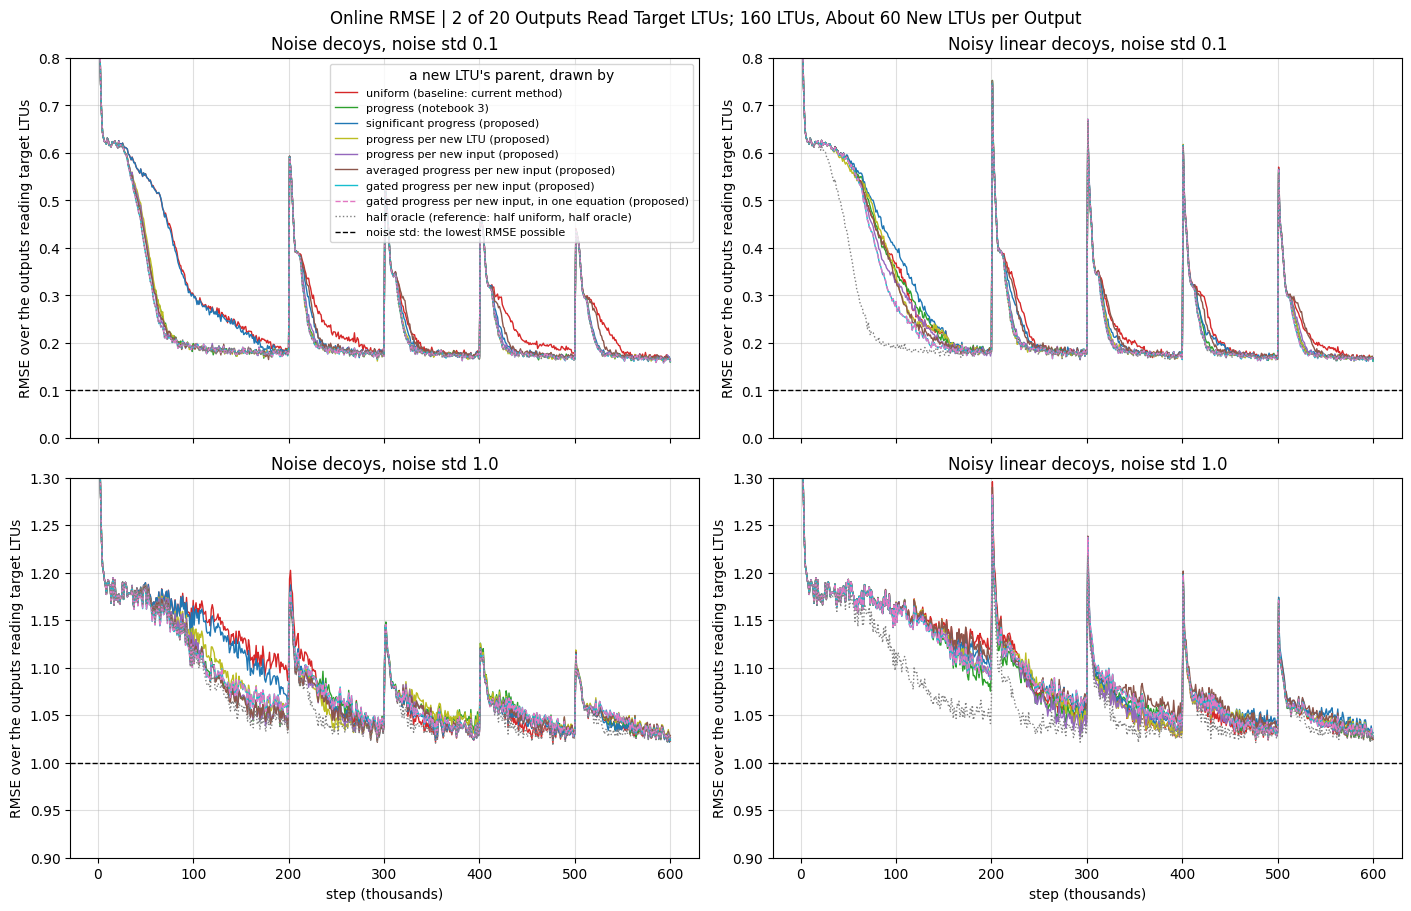

noise decoys, noise std 0.1, RMSE averaged over the run: uniform 0.284, progress 0.242, significant progress 0.270, progress per new LTU 0.242, progress per new input 0.243, averaged progress per new input 0.249, gated progress per new input 0.239, gated progress per new input, in one equation 0.239, half oracle 0.240
noise decoys, noise std 1.0, RMSE averaged over the run: uniform 1.087, progress 1.079, significant progress 1.084, progress per new LTU 1.081, progress per new input 1.077, averaged progress per new input 1.076, gated progress per new input 1.079, gated progress per new input, in one equation 1.079, half oracle 1.069
noisy linear decoys, noise std 0.1, RMSE averaged over the run: uniform 0.286, progress 0.276, significant progress 0.284, progress per new LTU 0.273, progress per new input 0.273, averaged progress per new input 0.280, gated progress per new input 0.266, gated progress per new input, in one equation 0.266, half oracle 0.243
noisy linear decoys, noise std 1.

In [7]:
YLIMS = [(0, 0.8), (0.9, 1.3)]   # zoomed at noise std 1, where the gaps shrink near the floor
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
fig, axes = plt.subplots(2, len(PROBLEMS), figsize=(14, 9), sharex=True, layout='constrained')
for column, (problem, decoys) in enumerate(PROBLEMS):
    for row, (noise, ylim) in enumerate(zip(NOISE_STDS, YLIMS)):
        ax = axes[row, column]
        for name, role, rule, color, style in RULES:
            ax.plot(STEPS / 1000, results[(*problem, noise, rule)].mean(0), color=color, ls=style, lw=1,
                    label=f'{name} ({role})')
        ax.axhline(noise, color='black', ls='--', lw=1, label='noise std: the lowest RMSE possible')
        ax.set(title=f'{decoys.capitalize()}, noise std {noise}', ylim=ylim,
               ylabel='RMSE over the outputs reading target LTUs')
        ax.grid(alpha=0.4)
for ax in axes[1]:
    ax.set(xlabel='step (thousands)')
axes[0, 0].legend(title="a new LTU's parent, drawn by", fontsize=8)
fig.suptitle('Online RMSE | 2 of 20 Outputs Read Target LTUs; 160 LTUs, About 60 New LTUs per Output')
plt.show()

for problem, decoys in PROBLEMS:
    for noise in NOISE_STDS:
        print(f'{decoys}, noise std {noise}, RMSE averaged over the run: '
              + ', '.join(f'{name} {results[(*problem, noise, rule)].mean():.3f}' for name, _, rule, _, _ in RULES))

## Events

How often the test finds a significant decrease in error, for each kind of output, with parents drawn by significant
progress. Noise decoys come from the problem with noise decoys, and noisy linear decoys from the other problem. A decoy
that becomes a target is a new target from its change on. Every event of a decoy is false. A gap in a line means no
event in that window.

noise std 0.1, outputs that need LTUs from the start (mean over both problems), share of steps with an event: 0.0244 (0k-1k), 0.9809 (1k-200k), 0.7506 (200k-600k)
noise std 0.1, new targets: decoys after they become targets (mean over both problems), share of steps with an event: nan (0k-1k), nan (1k-200k), 0.9772 (200k-600k)
noise std 0.1, noisy linear decoys, share of steps with an event: 0.0082 (0k-1k), 0.2723 (1k-200k), 0.0029 (200k-600k)
noise std 0.1, noise decoys, share of steps with an event: 0.0064 (0k-1k), 0.0026 (1k-200k), 0.0023 (200k-600k)
noise std 1.0, outputs that need LTUs from the start (mean over both problems), share of steps with an event: 0.0067 (0k-1k), 0.5559 (1k-200k), 0.4332 (200k-600k)
noise std 1.0, new targets: decoys after they become targets (mean over both problems), share of steps with an event: nan (0k-1k), nan (1k-200k), 0.3570 (200k-600k)
noise std 1.0, noisy linear decoys, share of steps with an event: 0.0082 (0k-1k), 0.2725 (1k-200k), 0.0028 (200k-

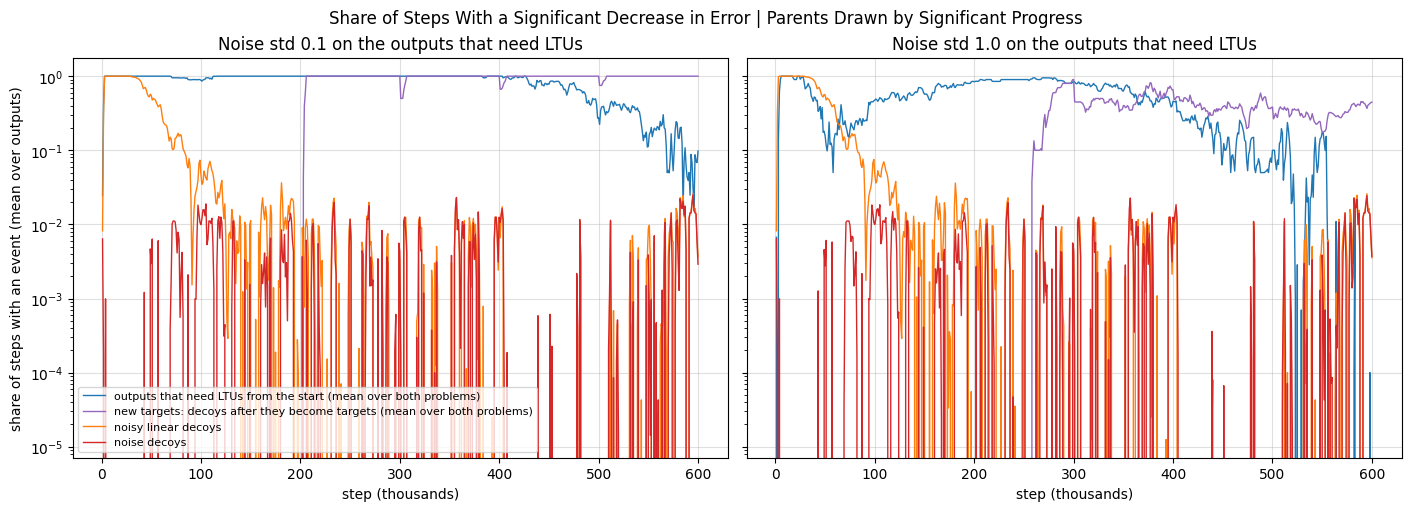

In [8]:
KINDS = [('outputs that need LTUs from the start (mean over both problems)', 'tab:blue'),
         ('new targets: decoys after they become targets (mean over both problems)', 'tab:purple'),
         ('noisy linear decoys', 'tab:orange'), ('noise decoys', 'tab:red')]
PHASES = [(0, 1), (1, 200), (200, 600)]   # thousands of steps
fig, axes = plt.subplots(1, len(NOISE_STDS), figsize=(14, 5), sharey=True, layout='constrained')
for ax, noise in zip(axes, NOISE_STDS):
    with_noise, with_linear = (events[(2, kind, noise, SIGNIFICANT)].mean(1) for kind in (NOISE, NOISY_LINEAR))
    shares = [(with_noise[0] + with_linear[0]) / 2, (with_noise[1] + with_linear[1]) / 2, with_linear[2],
              with_noise[2]]   # (window,) for each kind
    for share, (name, color) in zip(shares, KINDS):
        ax.plot(STEPS / 1000, share, color=color, lw=1, label=name)
        print(f'noise std {noise}, {name}, share of steps with an event: '
              + ', '.join(f'{share[a:b].mean():.4f} ({a}k-{b}k)' for a, b in PHASES))
    ax.set(title=f'Noise std {noise} on the outputs that need LTUs', yscale='log', xlabel='step (thousands)')
    ax.grid(alpha=0.4)
axes[0].set(ylabel='share of steps with an event (mean over outputs)')
axes[0].legend(fontsize=8)
fig.suptitle('Share of Steps With a Significant Decrease in Error | Parents Drawn by Significant Progress')
plt.show()

## Priorities

The mean priority $\sqrt{L_o}\, z_o$ of each kind of output at the end of each 1k-step window, with parents drawn by
significant progress. There are 2 outputs that need LTUs at the start and 18 decoys, so the decoys' total is 9 times
their mean. Then the same for progress, with priority $L_o (M_o - L_o) / M_o$, or 0 if negative, for progress per new LTU, for progress per new input, for averaged progress per new input, for gated progress per new input, and for the same in one equation.

significant progress, noise std 0.1, outputs that need LTUs from the start (mean over both problems), mean priority: 0.858 (0k-1k), 0.412 (1k-200k), 0.162 (200k-600k)
significant progress, noise std 0.1, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.28 (200k-600k)
significant progress, noise std 0.1, noisy linear decoys, mean priority: 1.28 (0k-1k), 0.752 (1k-200k), 0.18 (200k-600k)
significant progress, noise std 0.1, noise decoys, mean priority: 0.94 (0k-1k), 0.407 (1k-200k), 0.139 (200k-600k)
significant progress, noise std 1.0, outputs that need LTUs from the start (mean over both problems), mean priority: 1.09 (0k-1k), 1.02 (1k-200k), 0.813 (200k-600k)
significant progress, noise std 1.0, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.622 (200k-600k)
significant progress, noise std 1.0, noisy linear decoys, mean priority: 1.28 (0k-1k), 0.74

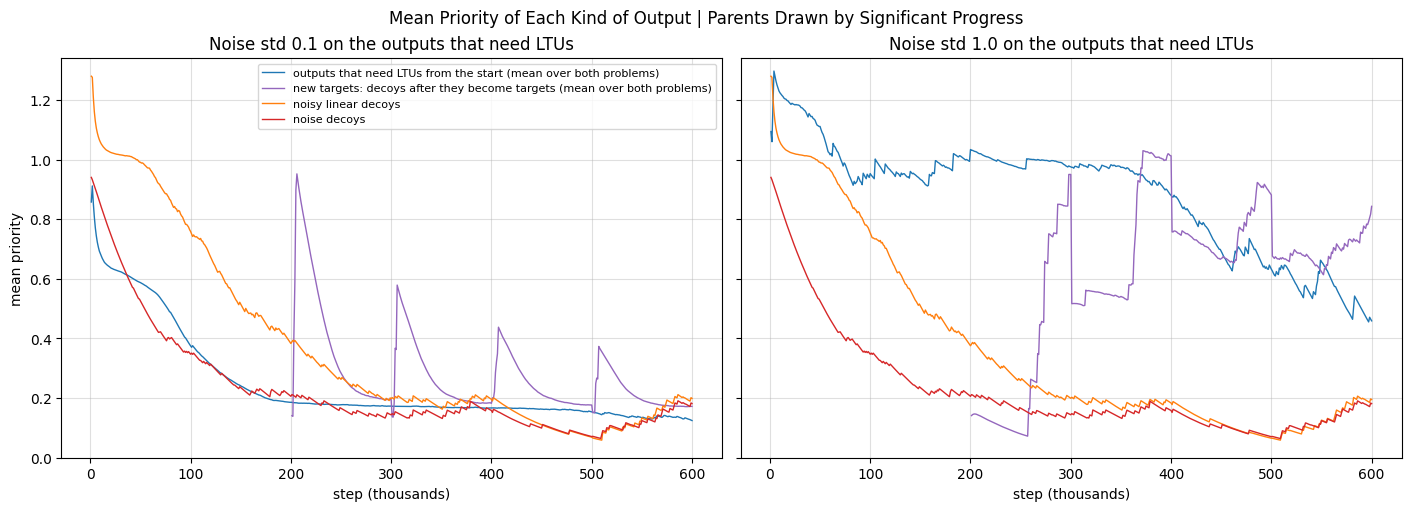

progress, noise std 0.1, outputs that need LTUs from the start (mean over both problems), mean priority: 0.00114 (0k-1k), 0.0334 (1k-200k), 0.00593 (200k-600k)
progress, noise std 0.1, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.0546 (200k-600k)
progress, noise std 0.1, noisy linear decoys, mean priority: 0.00188 (0k-1k), 0.0151 (1k-200k), 0.00438 (200k-600k)
progress, noise std 0.1, noise decoys, mean priority: 0.000328 (0k-1k), 0.00344 (1k-200k), 0.00402 (200k-600k)
progress, noise std 1.0, outputs that need LTUs from the start (mean over both problems), mean priority: 0.000738 (0k-1k), 0.0488 (1k-200k), 0.0294 (200k-600k)
progress, noise std 1.0, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.0236 (200k-600k)
progress, noise std 1.0, noisy linear decoys, mean priority: 0.00188 (0k-1k), 0.0151 (1k-200k), 0.00439 (200k-600k)
progress, noise s

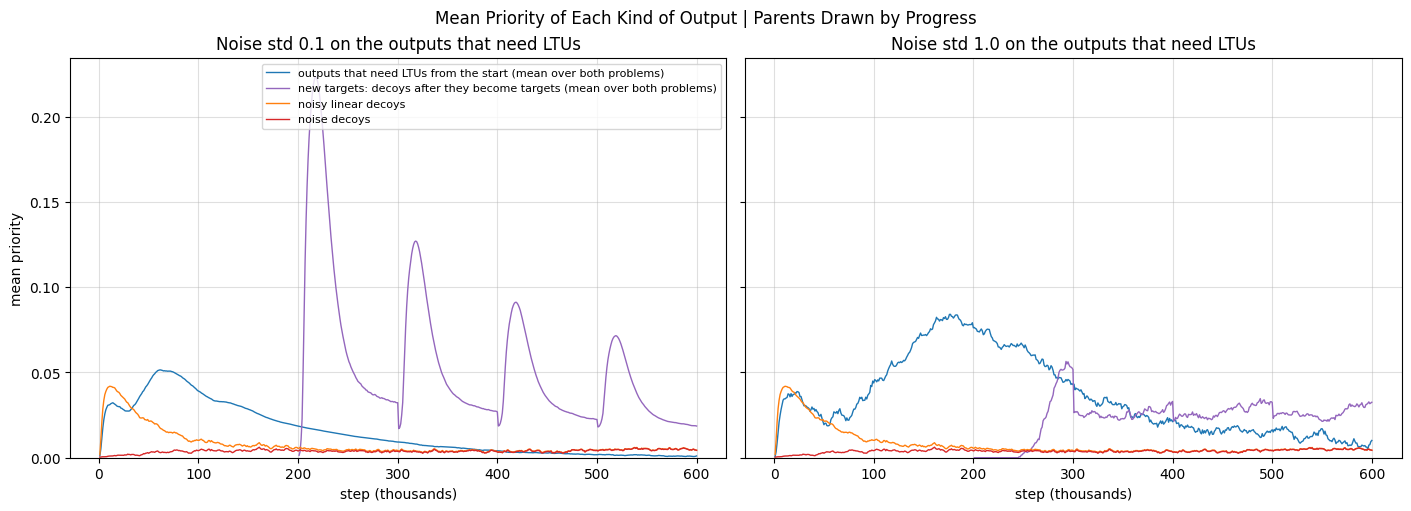

progress per new ltu, noise std 0.1, outputs that need LTUs from the start (mean over both problems), mean priority: 5.53e-05 (0k-1k), 0.00284 (1k-200k), 0.000687 (200k-600k)
progress per new ltu, noise std 0.1, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.00399 (200k-600k)
progress per new ltu, noise std 0.1, noisy linear decoys, mean priority: 7.26e-05 (0k-1k), 0.000774 (1k-200k), 0.000344 (200k-600k)
progress per new ltu, noise std 0.1, noise decoys, mean priority: 1.99e-05 (0k-1k), 0.000221 (1k-200k), 0.000325 (200k-600k)
progress per new ltu, noise std 1.0, outputs that need LTUs from the start (mean over both problems), mean priority: 2.01e-05 (0k-1k), 0.0013 (1k-200k), 0.000811 (200k-600k)
progress per new ltu, noise std 1.0, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.000801 (200k-600k)
progress per new ltu, noise std 1.0, noisy line

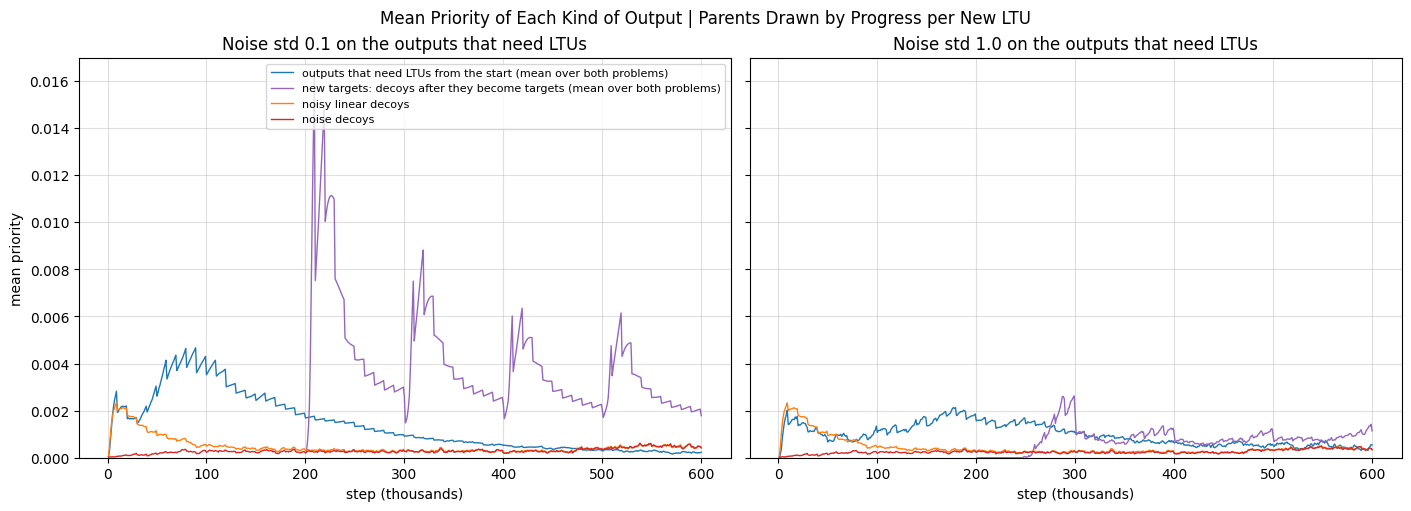

progress per new input, noise std 0.1, outputs that need LTUs from the start (mean over both problems), mean priority: 9.92e-07 (0k-1k), 0.000391 (1k-200k), 0.000391 (200k-600k)
progress per new input, noise std 0.1, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.00276 (200k-600k)
progress per new input, noise std 0.1, noisy linear decoys, mean priority: 1.29e-06 (0k-1k), 3.76e-05 (1k-200k), 0.000235 (200k-600k)
progress per new input, noise std 0.1, noise decoys, mean priority: 3.26e-07 (0k-1k), 1.63e-05 (1k-200k), 0.00022 (200k-600k)
progress per new input, noise std 1.0, outputs that need LTUs from the start (mean over both problems), mean priority: 3.58e-07 (0k-1k), 0.000187 (1k-200k), 0.0005 (200k-600k)
progress per new input, noise std 1.0, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.000596 (200k-600k)
progress per new input, noise std 1

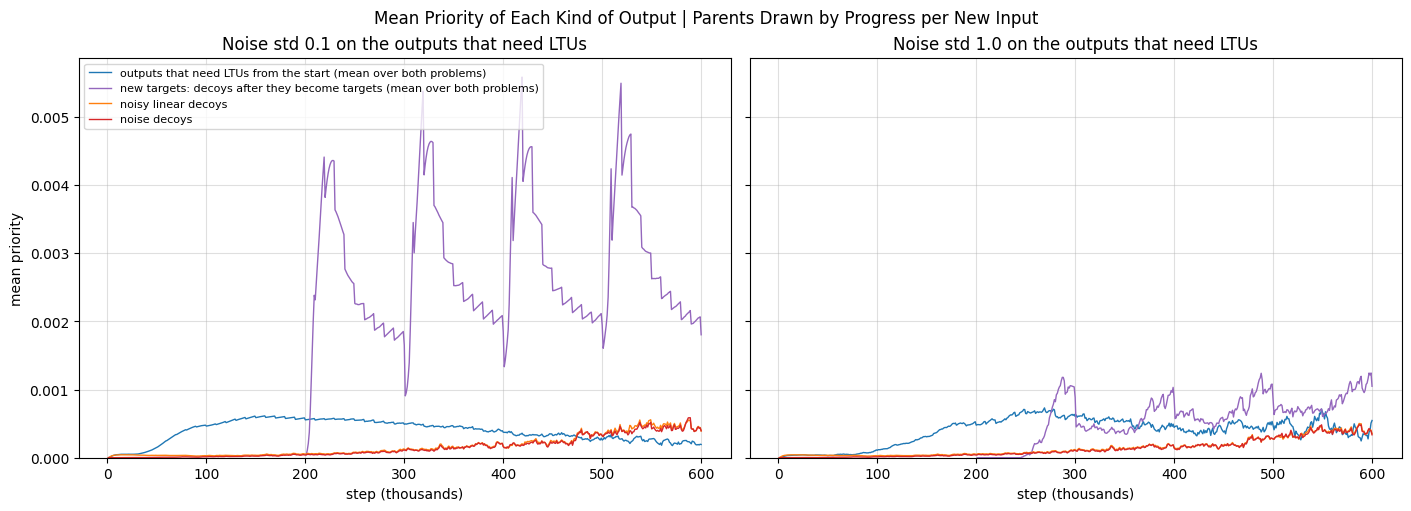

averaged progress per new input, noise std 0.1, outputs that need LTUs from the start (mean over both problems), mean priority: 4.56e-07 (0k-1k), 0.000262 (1k-200k), 0.000402 (200k-600k)
averaged progress per new input, noise std 0.1, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.00238 (200k-600k)
averaged progress per new input, noise std 0.1, noisy linear decoys, mean priority: 4.89e-07 (0k-1k), 3.21e-05 (1k-200k), 0.000103 (200k-600k)
averaged progress per new input, noise std 0.1, noise decoys, mean priority: 1.46e-07 (0k-1k), 4.47e-06 (1k-200k), 9.48e-05 (200k-600k)
averaged progress per new input, noise std 1.0, outputs that need LTUs from the start (mean over both problems), mean priority: 2.33e-07 (0k-1k), 9e-05 (1k-200k), 0.000401 (200k-600k)
averaged progress per new input, noise std 1.0, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.

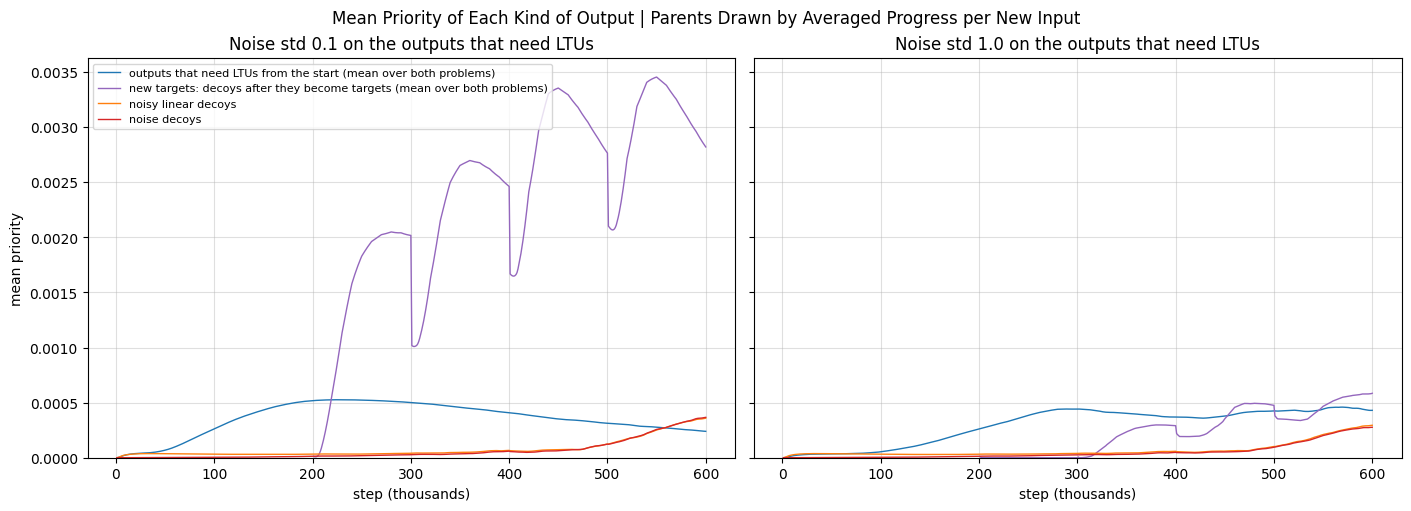

gated progress per new input, noise std 0.1, outputs that need LTUs from the start (mean over both problems), mean priority: 0 (0k-1k), 0.000357 (1k-200k), 0.000276 (200k-600k)
gated progress per new input, noise std 0.1, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.00233 (200k-600k)
gated progress per new input, noise std 0.1, noisy linear decoys, mean priority: 5.67e-08 (0k-1k), 1.03e-05 (1k-200k), 8.29e-06 (200k-600k)
gated progress per new input, noise std 0.1, noise decoys, mean priority: 0 (0k-1k), 2.16e-07 (1k-200k), 6.67e-06 (200k-600k)
gated progress per new input, noise std 1.0, outputs that need LTUs from the start (mean over both problems), mean priority: 0 (0k-1k), 0.00014 (1k-200k), 0.000209 (200k-600k)
gated progress per new input, noise std 1.0, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.000305 (200k-600k)
gated progress per

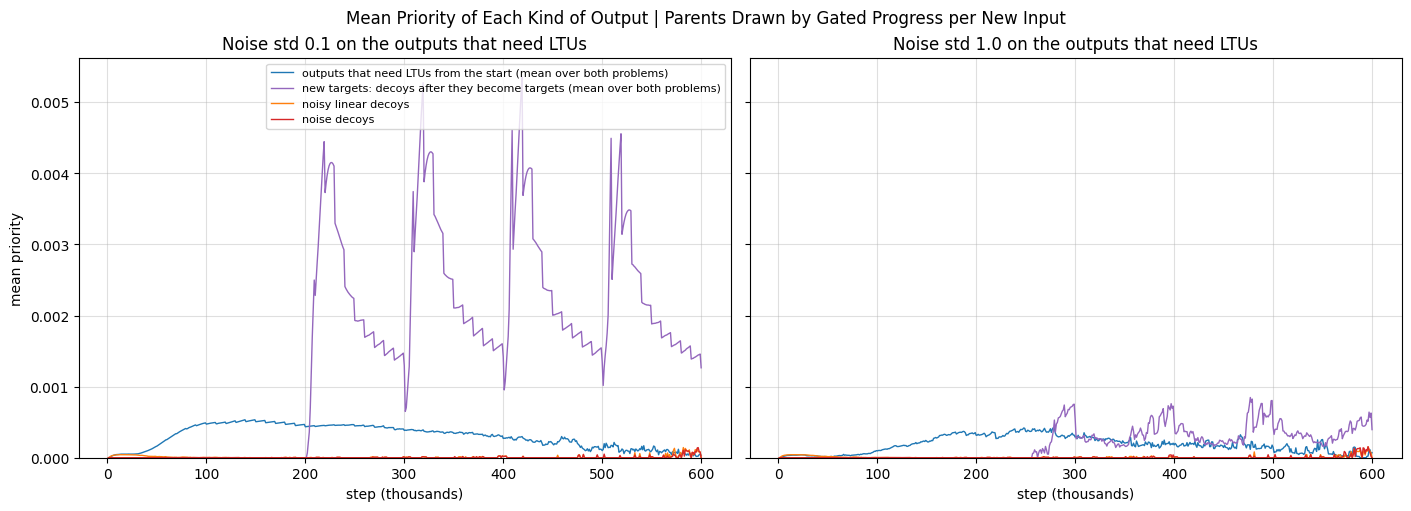

gated progress per new input, in one equation, noise std 0.1, outputs that need LTUs from the start (mean over both problems), mean priority: 0 (0k-1k), 0.000357 (1k-200k), 0.000276 (200k-600k)
gated progress per new input, in one equation, noise std 0.1, new targets: decoys after they become targets (mean over both problems), mean priority: nan (0k-1k), nan (1k-200k), 0.00233 (200k-600k)
gated progress per new input, in one equation, noise std 0.1, noisy linear decoys, mean priority: 5.67e-08 (0k-1k), 1.03e-05 (1k-200k), 8.29e-06 (200k-600k)
gated progress per new input, in one equation, noise std 0.1, noise decoys, mean priority: 0 (0k-1k), 2.16e-07 (1k-200k), 6.67e-06 (200k-600k)
gated progress per new input, in one equation, noise std 1.0, outputs that need LTUs from the start (mean over both problems), mean priority: 0 (0k-1k), 0.00014 (1k-200k), 0.000209 (200k-600k)
gated progress per new input, in one equation, noise std 1.0, new targets: decoys after they become targets (mean o

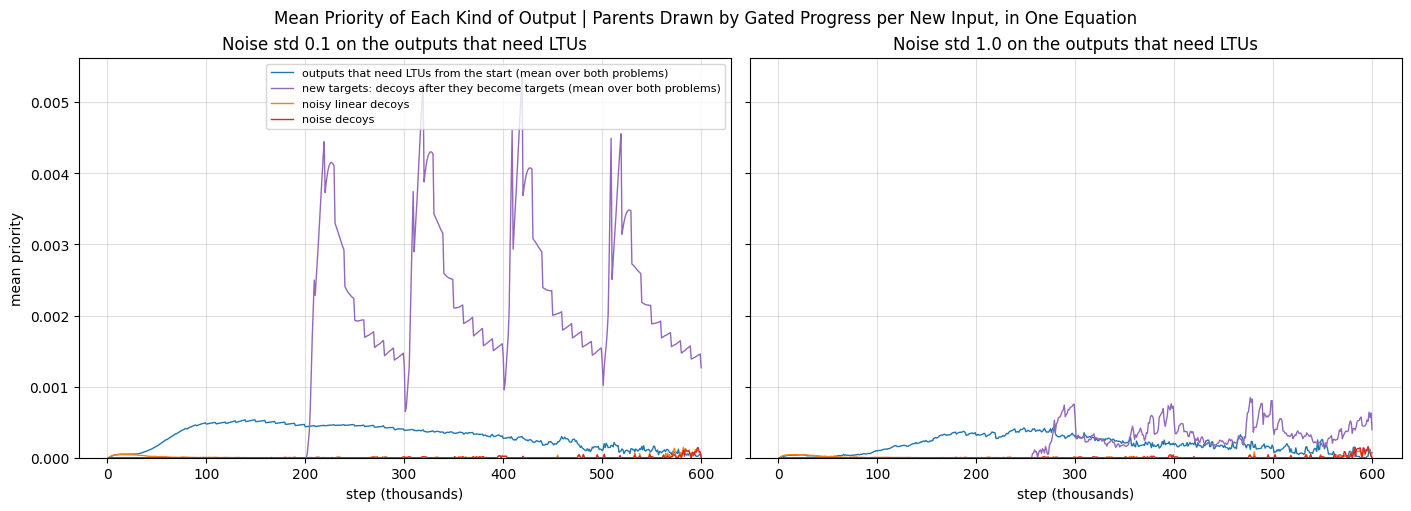

In [9]:
for rule_name, rule in [('Significant Progress', SIGNIFICANT), ('Progress', PROGRESS),
                        ('Progress per New LTU', PER_LTU), ('Progress per New Input', PER_INPUT),
                        ('Averaged Progress per New Input', AVERAGED), ('Gated Progress per New Input', GATED),
                        ('Gated Progress per New Input, in One Equation', ONE)]:
    fig, axes = plt.subplots(1, len(NOISE_STDS), figsize=(14, 5), sharey=True, layout='constrained')
    for ax, noise in zip(axes, NOISE_STDS):
        with_noise, with_linear = (priorities[(2, kind, noise, rule)].mean(1) for kind in (NOISE, NOISY_LINEAR))
        means = [(with_noise[0] + with_linear[0]) / 2, (with_noise[1] + with_linear[1]) / 2, with_linear[2],
                 with_noise[2]]   # (window,) for each kind
        for mean, (name, color) in zip(means, KINDS):
            ax.plot(STEPS / 1000, mean, color=color, lw=1, label=name)
            print(f'{rule_name.lower()}, noise std {noise}, {name}, mean priority: '
                  + ', '.join(f'{mean[a:b].mean():.3g} ({a}k-{b}k)' for a, b in PHASES))
        ax.set(title=f'Noise std {noise} on the outputs that need LTUs', xlabel='step (thousands)', ylim=(0, None))
        ax.grid(alpha=0.4)
    axes[0].set(ylabel='mean priority')
    axes[0].legend(fontsize=8)
    fig.suptitle(f'Mean Priority of Each Kind of Output | Parents Drawn by {rule_name}')
    plt.show()

## Results

**Significant progress does about as well as uniform parents**: RMSE averaged over the run 0.270 against 0.284 and
1.084 against 1.087 with noise decoys, and 0.284 against 0.286 and 1.098 against 1.095 with noisy linear decoys. It
does worse than progress (0.242, 1.079, 0.276 and 1.093), and it helps only after the changes, with noise decoys at
noise std 0.1.

**False events occur through the whole run** (Events plot). Noise decoys have an event at 0.6% of the steps in the
first 1k steps, and at about 0.25% of the steps after that, in bursts of many steps: about twice the 0.13% that 3
standard errors give at one step. Noisy linear decoys have an event at almost every step for the first 50k steps, while
the linear learner learns their linear part, and then the same 0.25%. The decoy lines are the same at both noise
levels, so the LTUs hardly change the decoys' error: the events come from the linear learner and from chance.

**New targets.** At noise std 0.1, a decoy that becomes a target has an event at almost every step from its change on.
At noise std 1, the first new target has no event for about 60k steps after its change: its error first rises, to
about 2, and $M_o$ still holds the lower error of its time as a decoy, so $M_o - L_o$ stays negative while the error
falls again.

**Priorities** (first Priorities plot). After 200k steps, at noise std 0.1, an output that needs LTUs from the start has
about the same mean priority as a decoy (0.16, against 0.18 for noisy linear decoys and 0.14 for noise decoys),
because its error is small. At noise std 1, it has about 5 times more (0.81). A new target's priority jumps at its
change at noise std 0.1, and then falls as its error falls; at noise std 1, it rises only when its events start. The
noise decoys' priority falls from 0.94 to about 0.2 over the first 200k steps, as $z$ decays after the events at the
start; after that, chance events keep it near 0.15.

**Progress priorities** (second Priorities plot). Over steps 1k to 200k, an output that needs LTUs has about 10 times
the mean priority of a noise decoy (0.033 and 0.049, against 0.003), where significant progress gives it about 1 and
2.5 times. After 200k steps, the new targets have the most priority, and at noise std 1 they get it only about 60k
steps after their change, as with significant progress.

**Why the rule fails.** One event sets $z$ to 1 for about 80k steps, so even 0.25% of the steps keeps the decoys' $z$
well above 0 (0.15 to 0.2 after 200k steps, in a pilot check). A decoy's error is about 1, much more than a learnable
output's, so with $\sqrt{L_o}\, z_o$ the 18 decoys take most of the half drawn by priority.

**Progress per new LTU and per new input do about as well as progress** (third and fourth Priorities plots): 0.242 and
0.243 with noise decoys at noise std 0.1, 1.081 and 1.077 at noise std 1, 0.273 and 0.273 with noisy linear decoys at
noise std 0.1, and 1.095 and 1.092 at noise std 1. Until about step 200k, the 401 linear inputs are most of each
output's count of new inputs, so per new input acts like progress. After that, the decoys' priority rises to that of
the outputs that need LTUs: their measured decrease is noise, and their count falls to their few new LTUs.

**Averaged progress per new input does about as well, or a little worse** (fifth Priorities plot): 0.249, 1.076, 0.280
and 1.101. After 200k steps, it gives the noise decoys about 2.5 times less priority than progress per new input
(9.5e-5 against 2.2e-4 at noise std 0.1, 7.7e-5 against 1.9e-4 at noise std 1). But at noise std 1, it also gives the
new targets about 2.5 times less (2.5e-4 against 6.0e-4): after a change, their error first rises, so their mean gain
goes below 0 and needs many steps to come back. The decoys' priority still rises over time, as their count falls.

**Gated progress per new input keeps the priority away from noise** (sixth Priorities plot). After 200k steps, a noise
decoy gets about 30 times less priority than with progress per new input (6.7e-6 against 2.2e-4 at noise std 0.1, and
7.5e-6 against 1.9e-4 at noise std 1). At noise std 1, a new target gets about 40 times the priority of a noise decoy,
against 3 times. At noise std 0.1, it does the best of the rules: 0.239 with noise decoys, as well as the half oracle
(0.240), and 0.266 with noisy linear decoys. At noise std 1, it does about as well as progress per new input (1.079 and
1.096).

**In one equation**, the draw gives exactly the same RMSE curves.